# MetaTwin-Guard — demonstrations, benchmark and conclusions (Google Colab)

Companion notebook to *An Explainable and Verifiable Digital Twin of a Two-Site Cyber Range for Metaverse
Infrastructure Assurance: Software Artifact and Field Protocol* (Korchenko, Prokopovych-Tkachenko, Davydenko,
Askerov, Herasymenko, Zhurov).

The notebook walks through every mechanism of the reference artifact and re-executes the deterministic synthetic
benchmark:

| § | Content | Article |
|---|---|---|
| 1 | Evidence levels and the confirmed two-site topology | §3.1–3.2, Fig. 1, Table 1 |
| 2 | Signed telemetry envelope (Ed25519, SHA-256) | §3.4, RFC 8032, FIPS 180-4 |
| 3 | Integrity gateway and the admission-before-state invariant | §3.5, Eqs. (1)–(2), Table 2 |
| 4 | Robust explainable detector, static rules, hybrid decision; decision traces | §3.6–3.7, §4.6, Eqs. (3)–(7) |
| 5 | Freshness / staleness of twin state | §3.5 |
| 6 | Quorum-signed evidence chain and its limits | §3.8, §4.7 |
| 7 | Deterministic benchmark: 6 scenarios × 8 runs, 17,280 events | §3.9, §4.2, Table 5, Fig. 4 |
| 8 | **Executed** layer ablation | Table 6 |
| 9 | Analytical and **executed** sensitivity | Table 7 |
| 10 | Timing and explanation outputs | §4.3 |
| 11 | Multi-seed robustness | Table 8 gate |
| 12 | Automated tests | §4.1, Table 4 |
| 13 | Conclusions | §4.5, §6 |

> **Evidence boundary.** All results here are *level B — deterministic synthetic software verification*. They are not
> cyber-range field evidence. The evidence ledger is a single-process emulation, not a distributed blockchain. The
> deterministic keys are test fixtures only.

**Run:** *Runtime → Run all*. A full run takes about 1–3 minutes on a standard Colab CPU runtime.


## 0. Setup

The package needs only `cryptography` (pre-installed on Colab) and `matplotlib`. If the Zenodo zip `MetaTwin-Guard-v1.0.0-zenodo.zip` has been uploaded to `/content`, it is used; otherwise the copy of the package embedded below (identical to release 1.0.0) is unpacked.

In [1]:
%pip install -q "cryptography>=42.0.5" matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import base64, io, os, sys, tarfile, zipfile, glob
from pathlib import Path

EMBEDDED = "..."

work = Path("metatwin_guard_src")
zips = sorted(glob.glob("/content/MetaTwin-Guard*.zip")) + sorted(glob.glob("MetaTwin-Guard*.zip"))
if Path("metatwin_guard/__init__.py").exists():
    work = Path(".")
    print("Using package from the current directory")
elif Path("../metatwin_guard/__init__.py").exists():
    work = Path("..")
    print("Using package from the parent directory (repository checkout)")
elif zips:
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(work)
    work = next(p.parent for p in work.rglob("metatwin_guard/__init__.py")).resolve()
    print("Using uploaded Zenodo zip:", zips[0])
else:
    work.mkdir(exist_ok=True)
    with tarfile.open(fileobj=io.BytesIO(base64.b64decode(EMBEDDED)), mode="r:gz") as tar:
        tar.extractall(work, **({"filter": "data"} if hasattr(tarfile, "data_filter") else {}))
    print("Using the embedded package copy")
sys.path.insert(0, str(work.resolve()))
os.environ["PYTHONPATH"] = str(work.resolve()) + os.pathsep + os.environ.get("PYTHONPATH", "")

import metatwin_guard as mtg, cryptography, platform
print("metatwin_guard", mtg.__version__, "| cryptography", cryptography.__version__, "| Python", platform.python_version())

Using the embedded package copy
metatwin_guard 1.0.0 | cryptography 50.0.1 | Python 3.13.16


In [3]:
import json, math, statistics, copy
from datetime import timedelta
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from metatwin_guard import config, topology, plots
from metatwin_guard import (MetaTwinGuard, SoftwareSensor, IntegrityGateway, QuorumEvidenceLedger,
                            RobustDetector, StaticRules, TwinState, deterministic_private_key, tamper_features)
from metatwin_guard.generator import START_TIME, normal_features
from metatwin_guard.detector import min_simultaneous_deviations
from metatwin_guard import benchmark as bm
import random

def md_table(rows, cols, fmt=None):
    fmt = fmt or {}
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for r in rows:
        out.append("| " + " | ".join(fmt.get(c, str)(r[c]) if c in r else "" for c in cols) + " |")
    display(Markdown("\n".join(out)))

## 1. Evidence levels and confirmed topology

* **Level A — confirmed context:** documented components of the two-site range.
* **Level B — software verification:** this artifact, unit tests, deterministic generator (everything executed below).
* **Level C — planned field method:** the prospective protocol (Supplementary File S1); no measurement exists.

Nominal provider rates are not measured throughput; unknown inventory items are left unknown rather than invented.

{
  "provider_connections": 7,
  "access_points": 54,
  "backup_power_stations": 3,
  "kali_workstations": 25,
  "inter_site_vpn": true
}
Not supplied: router firmware, controller versions, access-point models, switches, VLAN/ACL/IP plan, VPN protocol and MTU, Kali workstation hardware, EcoFlow models, capacity and loads, authorized telemetry export/API


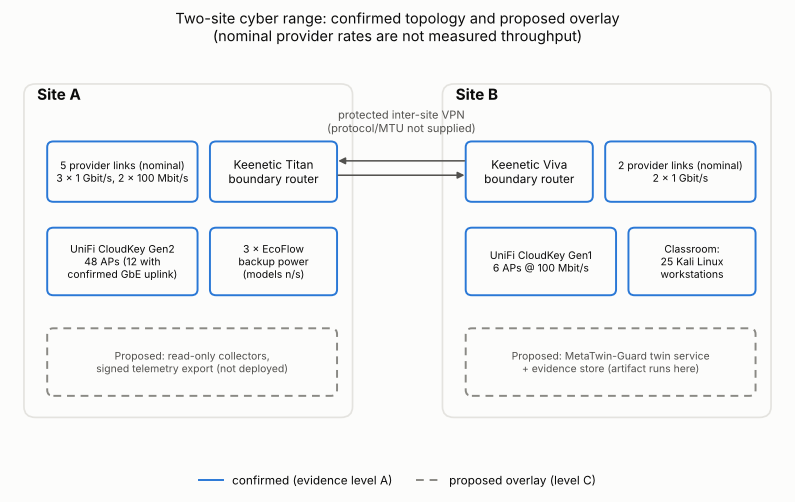

In [4]:
print(json.dumps(topology.summary(), indent=2))
print("Not supplied:", ", ".join(topology.NOT_SUPPLIED))
plots.figure_topology(); plt.show()

## 2. Signed telemetry envelope

A software sensor builds a canonical event (sorted-key JSON), hashes the feature payload with SHA-256 (FIPS 180-4),
links it to its previous event hash, and signs the envelope with Ed25519 (RFC 8032). `ingest_time_utc` is assigned on
receipt and is therefore outside the signature.

In [5]:
sensor = SoftwareSensor("sA-edge", "A", "A/edge-router", deterministic_private_key("sA-edge", config.MASTER_SEED))
rng = random.Random(1)
ev = sensor.emit(normal_features(rng, transients=False), START_TIME, 45.0, "demo", "baseline")
print(json.dumps({k: (v[:24] + "…" if isinstance(v, str) and len(v) > 40 else v) for k, v in ev.items()}, indent=2))

{
  "event_id": "demo:sA-edge:000001",
  "scenario_id": "demo",
  "phase": "baseline",
  "site_id": "A",
  "sensor_id": "sA-edge",
  "source_seq": 1,
  "event_time_utc": "2026-08-23T00:00:00.000000Z",
  "ingest_time_utc": "2026-08-23T00:00:00.045000Z",
  "topology_node": "A/edge-router",
  "schema_version": "1.0",
  "features": {
    "rtt_ms": 51.0173,
    "jitter_ms": 8.8989,
    "loss_pct": 0.3133,
    "throughput_mbps": 83.59,
    "auth_failures": 3.0,
    "vpn_status": 1.0,
    "power_status": 1.0
  },
  "payload_hash": "9f40eaf7e2c4cb3c5704b12f\u2026",
  "previous_hash": "000000000000000000000000\u2026",
  "signature": "99a85cf002d9948fcf0cd3fb\u2026"
}


## 3. Integrity gateway and admission-before-state invariant

$g(e_i)=C_{schema}\wedge C_{hash}\wedge C_{signature}\wedge C_{id}\wedge C_{sequence}\wedge C_{chain}$ (Eq. 1) and
$T_i = U(T_{i-1}, e_i)$ if $g(e_i)=1$, otherwise $T_{i-1}$ (Eq. 2).

Below, a guard ingests a clean baseline and then receives one legitimate event and six manipulations. For each we show
the reasons, whether the twin state hash changed, and that an evidence block was still written.

In [6]:
sensors = {sid: SoftwareSensor(sid, site, node, deterministic_private_key(sid, config.MASTER_SEED))
           for sid, (site, node) in topology.SENSORS.items()}
guard = MetaTwinGuard({s: x.private_key.public_key() for s, x in sensors.items()})
rng = random.Random(7); t = START_TIME
history = []
for i in range(120):
    t += timedelta(seconds=1)
    e = sensors[rng.choice(list(sensors))].emit(normal_features(rng), t, 45.0, "demo", "baseline")
    history.append(e); guard.process(e)
guard.fit_baseline()

s = sensors["s-vpn"]
def nxt(feats=None, dt=1):
    global t; t += timedelta(seconds=dt)
    return s.emit(feats or normal_features(rng, transients=False), t, 45.0, "demo", "evaluation")

legit = nxt()
cases = [("legitimate event", legit)]
cases.append(("replay of an accepted event", copy.deepcopy(history[10])))
e2 = nxt(); cases.append(("modified after signing (hash not fixed)", tamper_features(e2, {"rtt_ms": 420.0}, False)))
cases.append(("modified after signing (hash recomputed)", tamper_features(e2, {"rtt_ms": 420.0}, True)))
cases.append(("original of the modified event", e2))
rogue = SoftwareSensor("s-rogue", "A", "A/vpn-path", deterministic_private_key("s-rogue", 99))
cases.append(("unregistered key", rogue.emit(normal_features(rng), t, 45.0, "demo", "evaluation")))
e3, e4 = nxt(), nxt()
cases.append(("out-of-order: later event first", e4))
cases.append(("…then the earlier one", e3))
broken = dict(nxt()); broken.pop("signature"); cases.append(("malformed (missing signature)", broken))
cases.append(("next legitimate event after a lost one", nxt()))

rows = []
for name, e in cases:
    before, nblocks = guard.twin.state_hash(), len(guard.ledger.blocks)
    r = guard.process(e)
    rows.append({"case": name, "admitted": r["admitted"], "reasons": ", ".join(r["reasons"]) or "—",
                 "state changed": guard.twin.state_hash() != before, "evidence block": len(guard.ledger.blocks) == nblocks + 1,
                 "hybrid alert": r["hybrid_alert"]})
md_table(rows, ["case", "admitted", "reasons", "state changed", "evidence block", "hybrid alert"])

| case | admitted | reasons | state changed | evidence block | hybrid alert |
|---|---|---|---|---|---|
| legitimate event | True | — | True | True | False |
| replay of an accepted event | False | duplicate_event_id, non_increasing_sequence, previous_hash_mismatch | False | True | True |
| modified after signing (hash not fixed) | False | payload_hash_mismatch | False | True | True |
| modified after signing (hash recomputed) | False | signature_invalid | False | True | True |
| original of the modified event | True | — | True | True | False |
| unregistered key | False | unknown_sensor_key | False | True | True |
| out-of-order: later event first | False | previous_hash_mismatch | False | True | True |
| …then the earlier one | True | — | True | True | False |
| malformed (missing signature) | False | schema:missing_signature | False | True | True |
| next legitimate event after a lost one | False | previous_hash_mismatch | False | True | True |

**Observation.** Only admitted events change the state; every rejected event leaves a signed evidence record with
its reasons. Rejection of an earlier event that arrives after a later one is by design: legitimate re-ordering needs a
bounded buffer at the collector (field deployment), and the later event itself is rejected because its previous-hash
does not continue the accepted chain.

**Limitation made visible.** The last row shows that once a legitimate event is lost (here: the malformed one), the
gateway rejects every later event of that source, because its previous-hash no longer matches. The reference artifact
deliberately does not re-synchronize a source chain; gap reporting and authenticated re-synchronization belong to the
field collector and are listed in the extended verification suite.

## 4. Robust explainable detector, rules and hybrid decision

$s_j=\max(1.4826\,MAD_j,0.25)$ (Eq. 3, Rousseeuw & Croux 1993), $z_j=\min(20,|x_j-m_j|/s_j)$ (Eq. 4),
$A(x)=\sqrt{\tfrac1p\sum z_j^2}$ (Eq. 5), alert if $A\ge 3.20$, contributions $c_j=z_j/\sum_k z_k$ (Eq. 6),
hybrid $d_H=d_R\vee d_X\vee\neg g$ (Eq. 7).

First, the fitted baseline; then the three decision traces of §4.6, computed directly from the stated deviations.

In [7]:
det = guard.detector
md_table([{"feature": f, "median": det.median[f], "MAD": det.mad[f], "scale s_j": det.scale[f],
           "floor active": det.scale[f] == config.DISPERSION_FLOOR} for f in config.FEATURES],
         ["feature", "median", "MAD", "scale s_j", "floor active"],
         {c: (lambda v: f"{v:.3f}") for c in ("median", "MAD", "scale s_j")})

def trace(z):
    A = math.sqrt(sum(v*v for v in z.values()) / len(z)); tot = sum(z.values())
    top = sorted(((f, v/tot) for f, v in z.items()), key=lambda kv: -kv[1])[:3]
    return A, top
for name, z in [
    ("VPN path degradation", dict(rtt_ms=6.0, jitter_ms=5.2, loss_pct=4.4, throughput_mbps=2.0, auth_failures=0.3, vpn_status=0, power_status=0)),
    ("Replay (ordinary values)", dict(rtt_ms=0.6, jitter_ms=0.3, loss_pct=0.2, throughput_mbps=0.4, auth_failures=0.1, vpn_status=0, power_status=0)),
    ("Isolated power transition", dict(rtt_ms=0.8, jitter_ms=0.5, loss_pct=0.3, throughput_mbps=0.3, auth_failures=0.0, vpn_status=0, power_status=4.0)),
]:
    A, top = trace(z)
    print(f"{name:28s} A = {A:.2f}  flagged = {A >= config.SCORE_THRESHOLD}   top-3: " + ", ".join(f"{f} ({c:.2f})" for f, c in top))
print(f"\nSingle continuous feature must reach z = 3.20·√7 = {3.2*math.sqrt(7):.2f}; isolated binary flip gives A = √(16/7) = {math.sqrt(16/7):.2f}")

| feature | median | MAD | scale s_j | floor active |
|---|---|---|---|---|
| rtt_ms | 44.657 | 4.204 | 6.233 | False |
| jitter_ms | 6.294 | 1.470 | 2.179 | False |
| loss_pct | 0.333 | 0.144 | 0.250 | True |
| throughput_mbps | 91.018 | 7.310 | 10.837 | False |
| auth_failures | 3.000 | 1.000 | 1.483 | False |
| vpn_status | 1.000 | 0.000 | 0.250 | True |
| power_status | 1.000 | 0.000 | 0.250 | True |

VPN path degradation         A = 3.52  flagged = True   top-3: rtt_ms (0.34), jitter_ms (0.29), loss_pct (0.25)
Replay (ordinary values)     A = 0.31  flagged = False   top-3: rtt_ms (0.37), throughput_mbps (0.25), jitter_ms (0.19)
Isolated power transition    A = 1.56  flagged = False   top-3: power_status (0.68), rtt_ms (0.14), jitter_ms (0.08)

Single continuous feature must reach z = 3.20·√7 = 8.47; isolated binary flip gives A = √(16/7) = 1.51


In [8]:
# The same on live events through the full pipeline
x = normal_features(rng, transients=False)
for label, mod in [("ordinary", {}), ("VPN degradation", {"rtt_ms": x["rtt_ms"] + 160, "jitter_ms": 70, "loss_pct": 8}),
                   ("power transition", {"power_status": 0.0})]:
    t += timedelta(seconds=1)
    r = guard.process(sensors["sB-edge"].emit({**x, **mod}, t, 45.0, "demo", "evaluation"))
    print(f"{label:18s} admitted={r['admitted']}  rules={r['rules_fired'] or '-'}  A={r['robust_score']:.2f}  "
          f"robust={r['robust_alert']}  hybrid={r['hybrid_alert']}  top3={[(f, round(c, 2)) for f, c in r['top_contributions']]}")

ordinary           admitted=True  rules=-  A=0.87  robust=False  hybrid=False  top3=[('rtt_ms', 0.46), ('auth_failures', 0.35), ('throughput_mbps', 0.13)]
VPN degradation    admitted=True  rules=['rtt_ms>180', 'jitter_ms>50', 'loss_pct>5']  A=13.10  robust=True  hybrid=True  top3=[('rtt_ms', 0.32), ('jitter_ms', 0.32), ('loss_pct', 0.32)]
power transition   admitted=True  rules=['power_status<0.5']  A=1.74  robust=False  hybrid=True  top3=[('power_status', 0.51), ('rtt_ms', 0.23), ('auth_failures', 0.17)]


## 5. Freshness of twin state

Missing telemetry never changes the state (Eq. 2), so the twin must expose age: node state is *current*
($\Delta\le\tau_{fresh}$), *stale* or *unknown* ($\Delta>\tau_{lost}$). Bounds here are the artifact defaults
(30 s / 120 s); in the field they are preregistered.

In [9]:
for dt in (5, 60, 600):
    now = t + timedelta(seconds=dt)
    print(f"t_last + {dt:4d} s:", {n: guard.twin.freshness(n, now) for n in sorted(guard.twin.nodes)})

t_last +    5 s: {'A-B/vpn-path': 'current', 'A/ecoflow': 'current', 'A/edge-router': 'current', 'A/unifi-ck2': 'current', 'B/edge-router': 'current', 'B/unifi-ck1': 'current'}
t_last +   60 s: {'A-B/vpn-path': 'stale', 'A/ecoflow': 'stale', 'A/edge-router': 'stale', 'A/unifi-ck2': 'stale', 'B/edge-router': 'stale', 'B/unifi-ck1': 'stale'}
t_last +  600 s: {'A-B/vpn-path': 'unknown', 'A/ecoflow': 'unknown', 'A/edge-router': 'unknown', 'A/unifi-ck2': 'unknown', 'B/edge-router': 'unknown', 'B/unifi-ck1': 'unknown'}


## 6. Quorum-signed evidence chain

Each block binds the event hash, integrity result and reasons, anomaly score, decision, top contributions and the
twin-state hash; four validator keys sign the block hash and verification needs ≥ 3 valid signatures.

In [10]:
print("chain:", guard.ledger.verify().n_blocks, "blocks, valid =", guard.ledger.verify().valid)
print(json.dumps(guard.ledger.blocks[-3]["body"], indent=1)[:900], "…")

tests = {}
f = guard.ledger.tampered_copy(); f.blocks[50]["body"]["hybrid_alert"] = not f.blocks[50]["body"]["hybrid_alert"]
tests["flip a stored decision"] = f.verify()
f = guard.ledger.tampered_copy(); del f.blocks[40]
tests["delete a block"] = f.verify()
f = guard.ledger.tampered_copy(); f.blocks[30]["signatures"]["validator-1"] = "00"*64
tests["1 of 4 signatures invalid"] = f.verify()
f = guard.ledger.tampered_copy()
for v in ("validator-1", "validator-2"): f.blocks[30]["signatures"][v] = "00"*64
tests["2 of 4 signatures invalid"] = f.verify()
for k, rep in tests.items():
    print(f"{k:28s} valid={rep.valid}  {rep.errors[:1]}")

chain: 133 blocks, valid = True
{
 "index": 130,
 "previous_block_hash": "5c878101d1d4fd0abc4ace8af74ab206846c33c44e3a455e95d8ece77845b7ce",
 "event_id": "demo:sB-edge:000021",
 "event_payload_hash": "859c0390db85d3d629dadc17e30cff72a498596c2e0515089ff91081c0a85f50",
 "integrity_admitted": true,
 "integrity_reasons": [],
 "rules_fired": [],
 "anomaly_score": 0.868721,
 "hybrid_alert": false,
 "top_contributions": [
  [
   "rtt_ms",
   0.462166
  ],
  [
   "auth_failures",
   0.349642
  ],
  [
   "throughput_mbps",
   0.13217
  ]
 ],
 "twin_state_hash": "7d77b33ad7e673611e1e6dff5b98a1ca6fa42eac78afe9f7ec1dc178d5e43062"
} …


flip a stored decision       valid=False  ['block 50: body hash mismatch']
delete a block               valid=False  ['block 40: index mismatch']
1 of 4 signatures invalid    valid=True  []
2 of 4 signatures invalid    valid=False  ['block 30: 2/4 valid signatures < quorum 3']


**Limit made explicit.** All four keys live in one process: an adversary holding three keys (or the process)
can sign arbitrary blocks. The quorum fixes the evidence *format* and verification rule; it is not Byzantine fault
tolerance, and local append time is not blockchain confirmation time.

## 7. Deterministic synthetic benchmark (seed 20260823)

Six scenarios × eight runs; each run has 120 baseline and 240 evaluation events (40 injected, 200 normal):
48 runs, 17,280 events, 1,920 injected events. Three modes are scored on the same events.

48 runs, 17280 events, 1920 injected, all ledgers valid = True, state unchanged on every rejection = True  (20 s)


| Scenario | Mode | Precision | Recall | F1 | FP/1000 |
|---|---|---|---|---|---|
| WAN failover | Rules | 0.913 ± 0.031 | 0.909 ± 0.038 | 0.911 ± 0.024 | 17.5 ± 6.5 |
| WAN failover | Robust score | 0.819 ± 0.049 | 1.000 ± 0.000 | 0.900 ± 0.030 | 45.0 ± 14.6 |
| WAN failover | Hybrid | 0.815 ± 0.053 | 1.000 ± 0.000 | 0.897 ± 0.032 | 46.2 ± 16.0 |
| VPN degradation | Rules | 0.902 ± 0.035 | 0.953 ± 0.045 | 0.927 ± 0.039 | 20.6 ± 7.3 |
| VPN degradation | Robust score | 0.791 ± 0.033 | 1.000 ± 0.000 | 0.883 ± 0.020 | 53.1 ± 10.3 |
| VPN degradation | Hybrid | 0.791 ± 0.033 | 1.000 ± 0.000 | 0.883 ± 0.020 | 53.1 ± 10.3 |
| Wi-Fi authentication surge | Rules | 0.915 ± 0.060 | 0.719 ± 0.068 | 0.803 ± 0.049 | 13.8 ± 9.9 |
| Wi-Fi authentication surge | Robust score | 0.837 ± 0.073 | 0.844 ± 0.053 | 0.838 ± 0.038 | 34.4 ± 17.2 |
| Wi-Fi authentication surge | Hybrid | 0.835 ± 0.073 | 0.844 ± 0.053 | 0.836 ± 0.036 | 35.0 ± 17.3 |
| Power transition | Rules | 0.897 ± 0.029 | 1.000 ± 0.000 | 0.946 ± 0.016 | 23.1 ± 7.5 |
| Power transition | Robust score | 0.143 ± 0.075 | 0.038 ± 0.013 | 0.059 ± 0.022 | 48.8 ± 11.6 |
| Power transition | Hybrid | 0.795 ± 0.033 | 1.000 ± 0.000 | 0.886 ± 0.020 | 51.9 ± 10.3 |
| Telemetry modification | Rules | 0.927 ± 0.051 | 1.000 ± 0.000 | 0.962 ± 0.028 | 16.2 ± 12.7 |
| Telemetry modification | Robust score | 0.813 ± 0.054 | 1.000 ± 0.000 | 0.896 ± 0.033 | 46.9 ± 16.7 |
| Telemetry modification | Hybrid | 0.813 ± 0.054 | 1.000 ± 0.000 | 0.896 ± 0.033 | 46.9 ± 16.7 |
| Replay | Rules | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.000 ± 0.000 | 21.9 ± 7.0 |
| Replay | Robust score | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.000 ± 0.000 | 46.9 ± 15.3 |
| Replay | Hybrid | 0.811 ± 0.048 | 1.000 ± 0.000 | 0.895 ± 0.030 | 47.5 ± 14.9 |

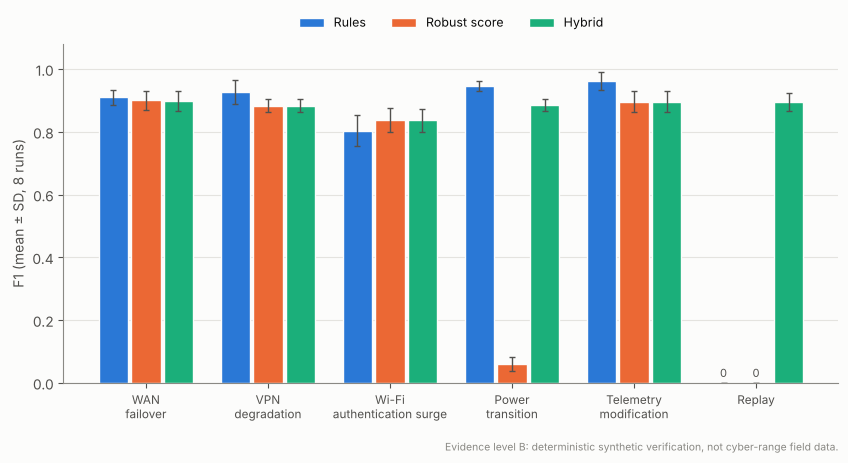

In [11]:
import time
t0 = time.time()
results, rows = bm.run_benchmark(config.MASTER_SEED, config.REPETITIONS)
summary = bm.summarize(rows)
print(f"{len(rows)} runs, {sum(r['n_events'] for r in rows)} events, {sum(r['n_injected'] for r in rows)} injected, "
      f"all ledgers valid = {all(r['ledger_valid'] for r in rows)}, "
      f"state unchanged on every rejection = {all(r['state_unchanged_on_reject'] for r in rows)}  ({time.time()-t0:.0f} s)")
ms = lambda k: (lambda r: f"{r[k+'_mean']:.3f} ± {r[k+'_sd']:.3f}")
md_table([{**r, "Scenario": config.SCENARIO_LABELS[r["scenario"]], "Mode": bm.MODE_LABELS[r["mode"]],
           "Precision": ms("precision")(r), "Recall": ms("recall")(r), "F1": ms("f1")(r),
           "FP/1000": f"{r['fp_per_1000_normal_mean']:.1f} ± {r['fp_per_1000_normal_sd']:.1f}"} for r in summary],
         ["Scenario", "Mode", "Precision", "Recall", "F1", "FP/1000"])
plots.figure_f1(summary); plt.show()

**Comparison with the article's Table 5 (mean F1).** The methods and constants are identical; the generator is an
independent implementation of the stated design, so values differ slightly while the pattern must agree.

In [12]:
ARTICLE_F1 = {"wan_failover": (0.913, 0.880, 0.880), "vpn_degradation": (0.911, 0.878, 0.878),
              "wifi_auth_surge": (0.813, 0.815, 0.815), "power_transition": (0.959, 0.071, 0.893),
              "telemetry_modification": (0.974, 0.931, 0.931), "replay": (0.000, 0.000, 0.879)}
S = {(r["scenario"], r["mode"]): r for r in summary}
cmp_rows = []
for sc, art in ARTICLE_F1.items():
    row = {"Scenario": config.SCENARIO_LABELS[sc]}
    for m, a in zip(("rules", "robust", "hybrid"), art):
        row[bm.MODE_LABELS[m]] = f"{S[(sc, m)]['f1_mean']:.3f} (article {a:.3f})"
    best = lambda vals: max(range(3), key=lambda i: vals[i])
    row["best mode agrees (±0.01)"] = best([S[(sc, m)]["f1_mean"] for m in ("rules", "robust", "hybrid")]) == best(art) or \
        abs(sorted([S[(sc, m)]["f1_mean"] for m in ("rules","robust","hybrid")])[-1] - sorted([S[(sc, m)]["f1_mean"] for m in ("rules","robust","hybrid")])[-2]) < 0.01
    cmp_rows.append(row)
md_table(cmp_rows, ["Scenario", "Rules", "Robust score", "Hybrid", "best mode agrees (±0.01)"])

| Scenario | Rules | Robust score | Hybrid | best mode agrees (±0.01) |
|---|---|---|---|---|
| WAN failover | 0.911 (article 0.913) | 0.900 (article 0.880) | 0.897 (article 0.880) | True |
| VPN degradation | 0.927 (article 0.911) | 0.883 (article 0.878) | 0.883 (article 0.878) | True |
| Wi-Fi authentication surge | 0.803 (article 0.813) | 0.838 (article 0.815) | 0.836 (article 0.815) | True |
| Power transition | 0.946 (article 0.959) | 0.059 (article 0.071) | 0.886 (article 0.893) | True |
| Telemetry modification | 0.962 (article 0.974) | 0.896 (article 0.931) | 0.896 (article 0.931) | True |
| Replay | 0.000 (article 0.000) | 0.000 (article 0.000) | 0.895 (article 0.879) | True |

## 8. Layer ablation — executed

The article derives integrity-only ($d=\neg g$) and rules + integrity ($d=d_R\vee\neg g$) analytically (Table 6) and
lists an executed ablation as an open gate. Here both configurations are executed on the same events.

| Scenario | Rules | Robust score | Hybrid | Integrity-only | Rules + integrity | article derived (int-only / rules+int) |
|---|---|---|---|---|---|---|
| WAN failover | 0.911 | 0.900 | 0.897 | 0.000 | 0.911 | 0.000 / ≈0.913 |
| VPN degradation | 0.927 | 0.883 | 0.883 | 0.000 | 0.927 | 0.000 / ≈0.911 |
| Wi-Fi authentication surge | 0.803 | 0.838 | 0.836 | 0.000 | 0.803 | 0.000 / ≈0.813 |
| Power transition | 0.946 | 0.059 | 0.886 | 0.000 | 0.946 | 0.000 / ≈0.959 |
| Telemetry modification | 0.962 | 0.896 | 0.896 | 1.000 | 0.962 | 1.000 / ≈0.974 |
| Replay | 0.000 | 0.000 | 0.895 | 1.000 | 0.948 | 1.000 / ≈0.954 |

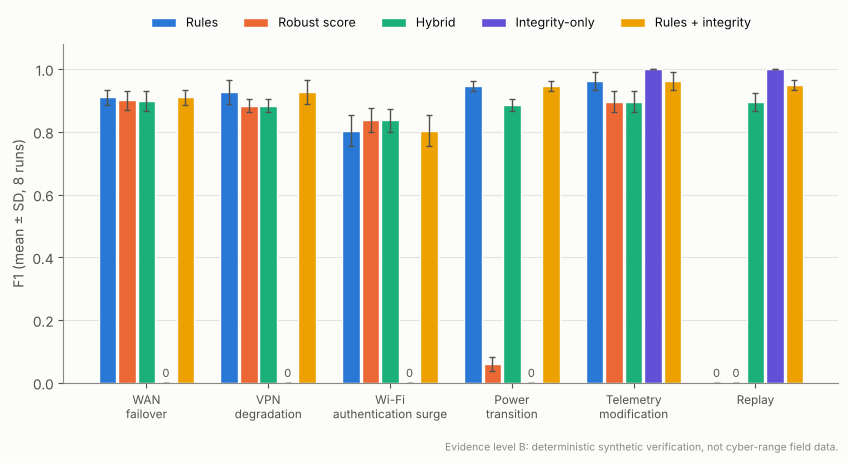

In [13]:
abl = bm.summarize(rows, bm.MODES)
A = {(r["scenario"], r["mode"]): r["f1_mean"] for r in abl}
ARTICLE_T6 = {"wan_failover": (0.0, 0.913), "vpn_degradation": (0.0, 0.911), "wifi_auth_surge": (0.0, 0.813),
              "power_transition": (0.0, 0.959), "telemetry_modification": (1.0, 0.974), "replay": (1.0, 0.954)}
md_table([{"Scenario": config.SCENARIO_LABELS[sc], **{bm.MODE_LABELS[m]: f"{A[(sc, m)]:.3f}" for m in bm.MODES},
           "article derived (int-only / rules+int)": f"{ARTICLE_T6[sc][0]:.3f} / ≈{ARTICLE_T6[sc][1]:.3f}"}
          for sc in config.SCENARIOS],
         ["Scenario"] + [bm.MODE_LABELS[m] for m in bm.MODES] + ["article derived (int-only / rules+int)"])
plots.figure_f1(abl, modes=bm.MODES, name="ablation"); plt.show()

## 9. Sensitivity of the robust score — analytical (Table 7) and executed

For a binary feature with constant baseline, $z=\min(20,1/s_{min})$ and the minimum number of simultaneous equal
deviations to reach $\tau$ is $k=\lceil p\tau^2/z^2\rceil$ ($p=7$).

| floor | z | isolated A | k at τ=2.5 | k at τ=3.2 | k at τ=4.0 |
|---|---|---|---|---|---|
| 0.1 | 10.0 | 3.78 | 1 | 1 | 2 |
| 0.25 | 4.0 | 1.51 | 3 | 5 | 7 |
| 0.5 | 2.0 | 0.76 | not reachable | not reachable | not reachable |

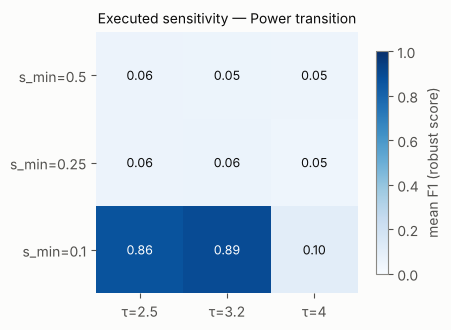

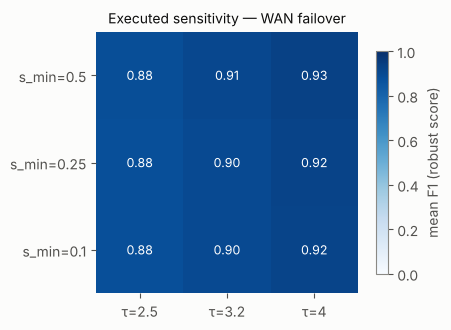

| floor | threshold | FP / 1000 normal (replay runs, robust only) |
|---|---|---|
| 0.1 | 2.5 | 57.5 |
| 0.1 | 3.2 | 46.9 |
| 0.1 | 4.0 | 38.8 |
| 0.25 | 2.5 | 57.5 |
| 0.25 | 3.2 | 46.9 |
| 0.25 | 4.0 | 38.8 |
| 0.5 | 2.5 | 57.5 |
| 0.5 | 3.2 | 45.0 |
| 0.5 | 4.0 | 34.4 |

In [14]:
tab = []
for fl in (0.10, 0.25, 0.50):
    z = min(20, 1/fl)
    row = {"floor": fl, "z": f"{z:.1f}", "isolated A": f"{math.sqrt(z*z/7):.2f}"}
    for th in (2.5, 3.2, 4.0):
        k = min_simultaneous_deviations(z, th); row[f"k at τ={th}"] = k if k else "not reachable"
    tab.append(row)
md_table(tab, ["floor", "z", "isolated A", "k at τ=2.5", "k at τ=3.2", "k at τ=4.0"])

sens = bm.sensitivity([r for r in results if r.run.scenario in ("power_transition", "wan_failover", "replay")])
for sc in ("power_transition", "wan_failover"):
    plots.figure_sensitivity(sens, sc); plt.show()
fp = {}
for r in sens:
    if r["scenario"] == "replay": fp.setdefault((r["floor"], r["threshold"]), []).append(r["fp_per_1000_normal"])
md_table([{"floor": f, "threshold": t, "FP / 1000 normal (replay runs, robust only)": f"{statistics.fmean(v):.1f}"} for (f, t), v in sorted(fp.items())],
         ["floor", "threshold", "FP / 1000 normal (replay runs, robust only)"])

**Observation.** The executed grid confirms the analytical prediction: with the reference floor 0.25 an isolated
power transition is (almost) never detected at any threshold, while floor 0.10 makes it detectable at τ ≤ 3.2. The
false-positive table shows the price of lower thresholds on continuous features — which is why the protocol prefers
explicit rules for binary indicators and preregistered feature-specific floors.

## 10. Timing and explanation outputs

Synchronization latency is *generator-defined* time; append time is local hashing + 4 signatures on this runtime.

In [15]:
ex = bm.scenario_extras(rows)
md_table([{"Scenario": config.SCENARIO_LABELS[e["scenario"]],
           "sync latency (ms)": f"{e['sync_latency_mean_ms_mean']:.1f}",
           "median append (ms)": f"{e['append_median_ms_mean']:.3f}",
           "top-3 hit rate": "n/a (no changed feature)" if math.isnan(e["explanation_top3_hit_rate_mean"]) else f"{e['explanation_top3_hit_rate_mean']:.3f}",
           "robust AUPRC": "n/a" if math.isnan(e["robust_auprc_mean"]) else f"{e['robust_auprc_mean']:.3f}"} for e in ex],
         ["Scenario", "sync latency (ms)", "median append (ms)", "top-3 hit rate", "robust AUPRC"])

| Scenario | sync latency (ms) | median append (ms) | top-3 hit rate | robust AUPRC |
|---|---|---|---|---|
| WAN failover | 154.9 | 0.171 | 1.000 | 0.995 |
| VPN degradation | 159.6 | 0.165 | 1.000 | 0.995 |
| Wi-Fi authentication surge | 46.0 | 0.165 | 1.000 | 0.830 |
| Power transition | 46.1 | 0.171 | 1.000 | 0.538 |
| Telemetry modification | 46.0 | 0.161 | 1.000 | 0.990 |
| Replay | 46.0 | 0.162 | n/a (no changed feature) | 0.155 |

## 11. Multi-seed robustness

The article lists additional master seeds as an open gate. Four further seeds (4 runs each, to keep runtime short) are executed here.

In [16]:
ms_rows = []
for seed in (1, 2, 3, 4):
    _, r = bm.run_benchmark(seed, 4)
    for x in bm.summarize(r, bm.MODES):
        ms_rows.append({"seed": seed, **x})
agg = {}
for r in ms_rows:
    agg.setdefault((r["scenario"], r["mode"]), []).append(r["f1_mean"])
md_table([{"Scenario": config.SCENARIO_LABELS[sc], **{bm.MODE_LABELS[m]: f"{min(agg[(sc, m)]):.3f}–{max(agg[(sc, m)]):.3f}" for m in bm.MODES}}
          for sc in config.SCENARIOS], ["Scenario"] + [bm.MODE_LABELS[m] for m in bm.MODES])

| Scenario | Rules | Robust score | Hybrid | Integrity-only | Rules + integrity |
|---|---|---|---|---|---|
| WAN failover | 0.867–0.902 | 0.880–0.908 | 0.880–0.908 | 0.000–0.000 | 0.867–0.902 |
| VPN degradation | 0.911–0.940 | 0.877–0.908 | 0.870–0.906 | 0.000–0.000 | 0.911–0.940 |
| Wi-Fi authentication surge | 0.814–0.832 | 0.801–0.852 | 0.801–0.850 | 0.000–0.000 | 0.814–0.832 |
| Power transition | 0.939–0.964 | 0.046–0.092 | 0.881–0.891 | 0.000–0.000 | 0.939–0.964 |
| Telemetry modification | 0.944–0.955 | 0.884–0.910 | 0.884–0.907 | 1.000–1.000 | 0.944–0.955 |
| Replay | 0.000–0.000 | 0.000–0.000 | 0.872–0.890 | 1.000–1.000 | 0.933–0.947 |

## 12. Automated tests

The five core tests of Table 4 plus 15 extended edge-case tests (unknown/wrong keys, malformed input, ID collision, delayed and out-of-order events, quorum limits, detector mathematics, determinism).

In [17]:
import subprocess
p = subprocess.run([sys.executable, "-m", "unittest", "discover", "-v", "tests"], cwd=str(work.resolve()),
                   capture_output=True, text=True)
lines = p.stderr.strip().splitlines()
print("\n".join(l.split(" (")[0] + " ... " + l.rsplit(" ", 1)[-1] for l in lines if l.endswith(("ok", "FAIL", "ERROR"))))
print("\n".join(lines[-3:]))

test_benchmark_outputs_and_ledger_verifies ... ok
test_clean_stream_accepted_and_state_updated ... ok
test_evidence_block_tampering_detected ... ok
test_post_signature_tamper_rejected ... ok
test_replay_rejected_state_unchanged_evidence_retained ... ok
test_contributions_sum_to_one_and_clip ... ok
test_isolated_binary_score_matches_paper ... ok
test_single_feature_trigger_level ... ok
test_table7_minimum_k ... ok
test_generator_is_deterministic ... ok
test_cross_source_id_collision_rejected ... ok
test_delayed_valid_event_admitted_but_stale ... ok
test_malformed_events_rejected_without_crash ... ok
test_out_of_order_delivery_rejected ... ok
test_unknown_sensor_rejected ... ok
test_wrong_key_signature_rejected ... ok
test_block_deletion_detected ... ok
test_one_bad_signature_still_meets_quorum ... ok
test_three_compromised_keys_can_forge ... ok
test_two_bad_signatures_break_quorum ... ok
Ran 20 tests in 2.984s

OK


## 13. Conclusions

Key numbers from this execution:

In [18]:
F = {(r["scenario"], r["mode"]): r for r in abl}
print(f"Replay:               rules F1={F[('replay','rules')]['f1_mean']:.3f}, robust F1={F[('replay','robust')]['f1_mean']:.3f}, "
      f"hybrid F1={F[('replay','hybrid')]['f1_mean']:.3f}, integrity-only F1={F[('replay','integrity_only')]['f1_mean']:.3f}")
print(f"Power transition:     rules F1={F[('power_transition','rules')]['f1_mean']:.3f}, robust F1={F[('power_transition','robust')]['f1_mean']:.3f} "
      f"(recall {F[('power_transition','robust')]['recall_mean']:.3f}), hybrid F1={F[('power_transition','hybrid')]['f1_mean']:.3f}")
print(f"Hybrid FP per 1000 normal events: {min(F[(s,'hybrid')]['fp_per_1000_normal_mean'] for s in config.SCENARIOS):.1f}–"
      f"{max(F[(s,'hybrid')]['fp_per_1000_normal_mean'] for s in config.SCENARIOS):.1f}  vs rules "
      f"{min(F[(s,'rules')]['fp_per_1000_normal_mean'] for s in config.SCENARIOS):.1f}–{max(F[(s,'rules')]['fp_per_1000_normal_mean'] for s in config.SCENARIOS):.1f}")
print(f"All {len(rows)} evidence chains valid: {all(r['ledger_valid'] for r in rows)}; rejected events never changed state: "
      f"{all(r['state_unchanged_on_reject'] for r in rows)}")

Replay:               rules F1=0.000, robust F1=0.000, hybrid F1=0.895, integrity-only F1=1.000
Power transition:     rules F1=0.946, robust F1=0.059 (recall 0.038), hybrid F1=0.886
Hybrid FP per 1000 normal events: 35.0–53.1  vs rules 13.8–23.1
All 48 evidence chains valid: True; rejected events never changed state: True


1. **Admission before state works as specified.** Replayed, modified (with or without a recomputed payload hash),
   unsigned, unknown-key, malformed and out-of-chain events were rejected, never changed the twin state, and still
   left a verifiable evidence record (§3, §12; all 48 benchmark chains valid).
2. **Authenticity, freshness and anomaly are different properties.** Replay leaves the feature vector ordinary, so both
   feature-only modes score F1 = 0; the hybrid detects it only through ¬g. The executed ablation confirms the article's
   derived Table 6: the replay and modification gain is attributable *entirely* to the integrity layer
   (integrity-only F1 = 1.000), and rules + integrity equals rules in all operational scenarios.
3. **Static rules dominate where a scenario crosses an explicit boundary**; the robust score is competitive only for the
   authentication surge, where a local baseline matters.
4. **The dispersion floor, not the threshold, decides binary detectability.** With $s_{min}=0.25$ an isolated
   power flip gives $A=\sqrt{16/7}\approx1.51<3.20$; robust-score F1 for power transition is ≈0.06, and the executed
   sensitivity grid reproduces the analytical Table 7 (floor 0.10 → detectable). Binary indicators belong in explicit
   rules or preregistered feature-specific floors.
5. **OR-fusion trades precision for coverage.** The hybrid inherits the robust score's false-positive rate (about two to
   three times that of rules), so it suits shared situational awareness and evidence, not direct paging; tiered alerts
   (integrity → operational rule → advisory score) are recommended for the field configuration.
6. **Explanations are faithful but not causal.** Top-3 contributions are the exact decomposition of the score and hit
   the manipulated features in the synthetic runs; they do not identify root causes.
7. **The findings are stable across seeds** (§11), but they remain *generator-level* results.
8. **Boundary.** Nothing here measures WAN switching, VPN recovery, wireless detection, EcoFlow autonomy, distributed-
   ledger behaviour or operator benefit. Those require the gated field protocol (S1) and its workbook (S2); synthetic
   timings (generator sync latency, sub-millisecond local append) must not be cited as network or blockchain
   performance.